## 10. Load and Explore the Real Astronaut Health Dataset

Load the actual dataset `astronaut_health_dataset_v2.csv` to understand its structure before retraining the models.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
from IPython.display import display



# ---------------------------------------------------------------- locate the dataset
DATA_FILENAME = 'astronaut_health_dataset_v2.csv'
_candidates = [
    DATA_FILENAME,
    f'./outputs/{DATA_FILENAME}',
    f'/mnt/data/{DATA_FILENAME}',
    f'/content/{DATA_FILENAME}',
    f'/mnt/user-data/uploads/{DATA_FILENAME}',
]
DATA_PATH = next((p for p in _candidates if os.path.isfile(p)), None)
if DATA_PATH is None:
    _found = glob.glob(f'**/{DATA_FILENAME}', recursive=True)
    DATA_PATH = _found[0] if _found else None
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find '{DATA_FILENAME}'. Put it next to this notebook "
        f"(or set DATA_PATH manually) and re-run this cell."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")

if 'timestamp' in df.columns:
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

# Deterministic order (rolling features were computed per astronaut in time order)
_sort_keys = [c for c in ['astronaut_id', 'mission_day', 'sample_id'] if c in df.columns]
if _sort_keys:
    df = df.sort_values(_sort_keys, kind='mergesort').reset_index(drop=True)

# ---------------------------------------------------------------- schema validation
REQUIRED_CORE = ['heart_rate', 'hrv_rmssd', 'sbp', 'dbp', 'core_temp', 'spo2',
                 'sleep_hours', 'mood_score', 'pvt_reaction_ms', 'fluid_intake_ml',
                 'co2_mmhg', 'radiation_msv', 'sans_trt_um', 'vo2max', 'mission_day']
REQUIRED_TARGETS = ['overall_status', 'alert_radiation', 'alert_gravity',
                    'alert_isolation', 'alert_distance', 'alert_environment']

_missing_targets = [c for c in REQUIRED_TARGETS if c not in df.columns]
if _missing_targets:
    raise KeyError(f"Target columns missing from dataset: {_missing_targets}")
if 'mission_day' not in df.columns:
    raise KeyError("'mission_day' is required for the temporal train/test split.")
_missing_core = [c for c in REQUIRED_CORE if c not in df.columns]
if _missing_core:
    print(f"WARNING - core sensor columns not found (they will be skipped in Step 11): {_missing_core}")

# ---------------------------------------------------------------- exploration
print(f"\nDataset shape: {df.shape}")
print(f"Memory usage : {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"\nColumns ({len(df.columns)}):")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

na = df.isna().sum()
na = na[na > 0].sort_values(ascending=False)
print("\nMissing values:", "none" if na.empty else "")
if not na.empty:
    display(na.to_frame('missing_count').assign(pct=lambda d: (d['missing_count'] / len(df) * 100).round(2)))

print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Mission days  : {df['mission_day'].min()} - {df['mission_day'].max()}")
if 'astronaut_id' in df.columns:
    print(f"Astronauts    : {df['astronaut_id'].nunique()} -> {sorted(df['astronaut_id'].unique())}")
if 'phase' in df.columns:
    print("\nRecords per mission phase:")
    print(df['phase'].value_counts())

print("\nTarget distributions (% of rows):")
_dist = pd.DataFrame({c: df[c].value_counts(normalize=True).mul(100).round(2)
                      for c in REQUIRED_TARGETS}).fillna(0)
display(_dist)

print("\nFirst 5 rows:")
display(df.head(), metadata={"alt": "Dataset preview"})
print("\nBasic statistics:")
display(df.describe().round(2), metadata={"alt": "Dataset statistics"})

Loaded: astronaut_health_dataset_v2.csv

Dataset shape: (26280, 68)
Memory usage : 17.3 MB

Columns (68):
['astronaut_id', 'mission_day', 'sample_id', 'timestamp', 'phase', 'heart_rate', 'hrv_rmssd', 'sbp', 'dbp', 'core_temp', 'spo2', 'sleep_hours', 'co2_mmhg', 'radiation_msv', 'mood_score', 'pvt_reaction_ms', 'vo2max', 'fluid_intake_ml', 'sans_trt_um', 'exercise_completed', 'spe_event', 'illness_flag', 'sleep_deprived', 'co2_spike', 'hazard_radiation', 'hazard_gravity', 'hazard_isolation', 'hazard_distance', 'hazard_environment', 'alert_radiation', 'alert_gravity', 'alert_isolation', 'alert_distance', 'alert_environment', 'overall_status', 'status_label', 'baseline_hr', 'baseline_hrv_rmssd', 'baseline_sbp', 'baseline_dbp', 'baseline_spo2', 'hr_deviation', 'hrv_deviation', 'sbp_deviation', 'dbp_deviation', 'spo2_deviation', 'heart_rate_7d_mean', 'heart_rate_7d_std', 'hrv_rmssd_7d_mean', 'hrv_rmssd_7d_std', 'sbp_7d_mean', 'sbp_7d_std', 'dbp_7d_mean', 'dbp_7d_std', 'core_temp_7d_mean', '

,overall_status,alert_radiation,alert_gravity,alert_isolation,alert_distance,alert_environment
0,94.78,99.13,98.74,97.29,99.61,99.38
1,4.42,0.78,1.26,2.19,0.23,0.55
2,0.80,0.09,0.00,0.52,0.16,0.07



First 5 rows:


,astronaut_id,mission_day,sample_id,timestamp,phase,heart_rate,hrv_rmssd,sbp,dbp,core_temp,...,sleep_hours_7d_mean,sleep_hours_7d_std,mood_score_7d_mean,mood_score_7d_std,pvt_reaction_ms_7d_mean,pvt_reaction_ms_7d_std,radiation_risk,gravity_risk,isolation_risk,environment_risk
0,ASTRO_001,1,0,2030-01-01 00:00:00,launch_adaptation,59.503,44.205,105.656,63.988,36.585,...,5.967,0.00,68.532,0.000,227.490,0.000,0.000,0.0,0.0,0.665
1,ASTRO_001,1,1,2030-01-01 06:00:00,launch_adaptation,66.895,38.085,113.914,71.079,36.922,...,5.967,0.00,68.532,0.000,227.490,0.000,0.000,0.0,0.0,0.772
2,ASTRO_001,1,2,2030-01-01 12:00:00,launch_adaptation,92.767,24.531,126.128,71.469,38.115,...,5.967,0.00,68.532,0.000,227.490,0.000,0.001,0.0,0.0,0.678
3,ASTRO_001,1,3,2030-01-01 18:00:00,launch_adaptation,74.430,43.226,111.096,75.102,37.035,...,5.967,0.00,68.532,0.000,227.490,0.000,0.001,0.0,0.0,0.689
4,ASTRO_001,2,0,2030-01-02 00:00:00,launch_adaptation,61.299,61.802,109.462,67.199,36.410,...,6.119,0.34,70.083,3.468,227.075,0.928,0.001,0.0,0.0,0.728



Basic statistics:


,mission_day,sample_id,timestamp,heart_rate,hrv_rmssd,sbp,dbp,core_temp,spo2,sleep_hours,...,sleep_hours_7d_mean,sleep_hours_7d_std,mood_score_7d_mean,mood_score_7d_std,pvt_reaction_ms_7d_mean,pvt_reaction_ms_7d_std,radiation_risk,gravity_risk,isolation_risk,environment_risk
count,26280.00,26280.00,26280,26280.00,26280.00,26280.00,26280.00,26280.00,26280.00,26280.00,...,26280.00,26280.00,26280.00,26280.00,26280.00,26280.00,26280.00,26280.00,26280.00,26280.00
mean,548.00,1.50,2031-07-02 09:00:00,70.23,47.31,120.94,68.23,37.87,97.95,6.61,...,6.61,0.99,69.21,4.62,216.74,8.66,1.01,0.28,0.18,0.61
min,1.00,0.00,2030-01-01 00:00:00,46.86,16.62,89.92,46.36,36.34,95.13,3.50,...,3.51,0.00,36.58,0.00,191.91,0.00,0.00,0.00,0.00,0.16
25%,274.00,0.75,2030-10-01 16:30:00,61.99,37.32,114.49,63.23,37.37,97.56,5.84,...,6.21,0.79,65.46,3.68,206.73,6.74,0.66,0.20,0.00,0.63
50%,548.00,1.50,2031-07-02 09:00:00,66.72,46.24,120.98,68.79,37.71,97.96,6.64,...,6.62,0.97,68.54,4.55,213.61,8.39,0.96,0.29,0.10,0.70
75%,822.00,2.25,2032-04-01 01:30:00,76.80,57.05,127.37,73.18,38.18,98.34,7.40,...,7.01,1.18,73.34,5.44,228.01,10.28,1.56,0.37,0.27,0.74
max,1095.00,3.00,2032-12-30 18:00:00,107.45,104.38,154.70,89.40,40.23,99.99,9.50,...,8.68,1.98,82.70,9.98,265.29,21.47,1.74,0.67,1.66,1.28
std,316.11,1.12,NaN,11.81,14.38,9.34,6.72,0.74,0.58,1.16,...,0.57,0.28,5.16,1.32,11.99,2.71,0.50,0.13,0.23,0.21


## 11. Prepare Features and Targets from Real Dataset

Extract feature columns, target variables, and split data temporally for training the ensemble model.

In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

STATUS_LABELS = ['GREEN', 'ORANGE', 'RED']
HAZARD_NAMES = ['radiation', 'gravity', 'isolation', 'distance', 'environment']
ALERT_COLS = [f'alert_{h}' for h in HAZARD_NAMES]
_LABEL_TO_INT = {'GREEN': 0, 'ORANGE': 1, 'RED': 2}

def to_status_int(series):
    """Accept 0/1/2 or GREEN/ORANGE/RED (any case) and return numeric codes."""
    if series.dtype == object or str(series.dtype).startswith('string') or str(series.dtype) == 'category':
        return series.astype(str).str.strip().str.upper().map(_LABEL_TO_INT)
    return pd.to_numeric(series, errors='coerce')

# ---------------------------------------------------------------- clean targets
df['overall_status'] = to_status_int(df['overall_status'])
for _c in ALERT_COLS:
    df[_c] = to_status_int(df[_c])

_n_before = len(df)
_valid = df[['overall_status'] + ALERT_COLS].isin([0, 1, 2]).all(axis=1) & df['mission_day'].notna()
df = df[_valid].reset_index(drop=True)
if len(df) < _n_before:
    print(f"Dropped {_n_before - len(df):,} rows with missing/invalid targets")
for _c in ['overall_status'] + ALERT_COLS:
    df[_c] = df[_c].astype(int)

# ---------------------------------------------------------------- feature definition
vital_cols = ['heart_rate', 'hrv_rmssd', 'sbp', 'dbp', 'core_temp', 'spo2']
behavioral_cols = ['sleep_hours', 'mood_score', 'pvt_reaction_ms', 'fluid_intake_ml']
mission_cols = ['co2_mmhg', 'radiation_msv', 'sans_trt_um', 'vo2max']
hazard_cols = ['hazard_radiation', 'hazard_gravity', 'hazard_isolation', 'hazard_distance', 'hazard_environment']
deviation_cols = ['hr_deviation', 'hrv_deviation', 'sbp_deviation', 'dbp_deviation', 'spo2_deviation']

def _is_leaky(name):
    n = name.lower()
    return 'alert' in n or 'status' in n

rolling_mean_cols = [c for c in df.columns if c.endswith('_7d_mean') and not _is_leaky(c)]
rolling_std_cols = [c for c in df.columns if c.endswith('_7d_std') and not _is_leaky(c)]
risk_cols = ['radiation_risk', 'gravity_risk', 'isolation_risk', 'environment_risk']

_wanted = (vital_cols + behavioral_cols + mission_cols + hazard_cols + deviation_cols +
           rolling_mean_cols + rolling_std_cols + risk_cols + ['mission_day'])
_wanted = list(dict.fromkeys(_wanted))                       # de-duplicate, keep order
feature_cols = [c for c in _wanted if c in df.columns and not _is_leaky(c)]
_dropped = [c for c in _wanted if c not in feature_cols]
if _dropped:
    print(f"NOTE - features not present in dataset and skipped: {_dropped}")

# Safety net: no target / label information may be used as an input feature
assert not any(_is_leaky(c) for c in feature_cols), "Target leakage detected in feature_cols"

# ---------------------------------------------------------------- matrices
X = (df[feature_cols].apply(pd.to_numeric, errors='coerce')
                     .replace([np.inf, -np.inf], np.nan)
                     .fillna(0)
                     .astype(float))
y = df['overall_status'].astype(int)
y_multi = df[ALERT_COLS].values.astype(int)

# ---------------------------------------------------------------- temporal split (first 80% of mission)
MISSION_DAYS = int(df['mission_day'].max())
split_day = int(MISSION_DAYS * 0.8)
train_mask = (df['mission_day'] <= split_day).values

if train_mask.sum() == 0 or (~train_mask).sum() == 0:
    raise ValueError("Temporal split produced an empty train or test set - check 'mission_day'.")

X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]
y_multi_train, y_multi_test = y_multi[train_mask], y_multi[~train_mask]

# ---------------------------------------------------------------- scaling (fit on train only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Features: {len(feature_cols)}")
print(f"Training: {len(X_train):,} samples (days 1-{split_day})")
print(f"Testing : {len(X_test):,} samples (days {split_day + 1}-{MISSION_DAYS})")
print("\nTarget distribution (train):")
print(y_train.value_counts().sort_index().rename(index=dict(enumerate(STATUS_LABELS))))
print("\nTarget distribution (test):")
print(y_test.value_counts().sort_index().rename(index=dict(enumerate(STATUS_LABELS))))

Features: 47
Training: 21,024 samples (days 1-876)
Testing : 5,256 samples (days 877-1095)

Target distribution (train):
overall_status
GREEN     19757
ORANGE     1057
RED         210
Name: count, dtype: int64

Target distribution (test):
overall_status
GREEN     5151
ORANGE     105
Name: count, dtype: int64


## 12. Train Ensemble Model on Real Dataset

Train Isolation Forest for anomaly detection and Gradient Boosting classifiers for health status and per-hazard predictions.

In [3]:
import time
import warnings
import numpy as np
from sklearn.ensemble import IsolationForest, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier

warnings.filterwarnings('ignore')

def fit_safe_classifier(X_fit, y_fit, **params):
    """Gradient Boosting; falls back to a majority-class model if only one class is present."""
    if len(np.unique(y_fit)) < 2:
        model = DummyClassifier(strategy='most_frequent')
    else:
        model = GradientBoostingClassifier(random_state=42, **params)
    model.fit(X_fit, y_fit)
    return model

def predict_hazard_matrix(models, X_enh):
    """Per-hazard predictions -> array of shape (n_samples, 5) in HAZARD_NAMES order."""
    return np.column_stack([models[h].predict(X_enh) for h in HAZARD_NAMES]).astype(int)

t0 = time.time()

# 1) ISOLATION FOREST - unsupervised anomaly score (fit on training data only)
print("[1/3] Training Isolation Forest ...")
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.15,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_train_scaled)

train_anomaly_scores = iso_forest.decision_function(X_train_scaled)
test_anomaly_scores = iso_forest.decision_function(X_test_scaled)

X_train_enhanced = np.column_stack([X_train_scaled, train_anomaly_scores])
X_test_enhanced = np.column_stack([X_test_scaled, test_anomaly_scores])
print(f"      done ({time.time() - t0:.1f}s)")

# 2) GRADIENT BOOSTING - overall GREEN / ORANGE / RED status
print("[2/3] Training overall-status Gradient Boosting ...")
t1 = time.time()
gb_model = fit_safe_classifier(
    X_train_enhanced, np.asarray(y_train).astype(int),
    n_estimators=150, max_depth=6, learning_rate=0.1, subsample=0.8
)
print(f"      done ({time.time() - t1:.1f}s)")

# 3) PER-HAZARD CLASSIFIERS - one model per Five-Hazards target
print("[3/3] Training per-hazard classifiers ...")
t2 = time.time()
hazard_models = {}
for i, hazard in enumerate(HAZARD_NAMES):
    hazard_models[hazard] = fit_safe_classifier(
        X_train_enhanced, y_multi_train[:, i],
        n_estimators=100, max_depth=5, learning_rate=0.1
    )
    print(f"      {hazard:12s} classes seen in train: {sorted(np.unique(y_multi_train[:, i]).tolist())}")
print(f"      done ({time.time() - t2:.1f}s)")

# Predictions on the held-out (last 20% of mission) test set
y_pred_overall = gb_model.predict(X_test_enhanced).astype(int)
y_pred_hazards = predict_hazard_matrix(hazard_models, X_test_enhanced)

print(f"\nTotal training time: {time.time() - t0:.1f}s")
print(f"Test predictions: overall={y_pred_overall.shape}, hazards={y_pred_hazards.shape}")

[1/3] Training Isolation Forest ...


      done (0.6s)
[2/3] Training overall-status Gradient Boosting ...


      done (173.0s)
[3/3] Training per-hazard classifiers ...


      radiation    classes seen in train: [0, 1, 2]


      gravity      classes seen in train: [0, 1]


      isolation    classes seen in train: [0, 1, 2]


      distance     classes seen in train: [0, 1, 2]


      environment  classes seen in train: [0, 1, 2]
      done (425.0s)

Total training time: 598.6s
Test predictions: overall=(5256,), hazards=(5256, 5)


## 13. Evaluate the Model on the Real Dataset

Report overall accuracy, balanced accuracy and macro-F1, a full classification report, and per-hazard metrics. Because this is a safety system, we also track **RED recall** (how many true RED events were caught) and the number of RED events that were missed completely (predicted GREEN).

In [4]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             precision_score, recall_score)

LABELS = [0, 1, 2]
y_train_arr = np.asarray(y_train).astype(int)
y_test_arr = np.asarray(y_test).astype(int)
y_pred_train = gb_model.predict(X_train_enhanced).astype(int)

def macro_f1_present(y_true, y_pred):
    """Macro-F1 over the classes that actually occur (avoids absent classes counting as 0)."""
    present = sorted(set(np.unique(y_true).tolist()) | set(np.unique(y_pred).tolist()))
    return f1_score(y_true, y_pred, labels=present, average='macro', zero_division=0)

def class_recall(y_true, y_pred, cls):
    if (y_true == cls).sum() == 0:
        return float('nan')
    return recall_score(y_true, y_pred, labels=[cls], average='macro', zero_division=0)

def class_precision(y_true, y_pred, cls):
    if (y_pred == cls).sum() == 0:
        return float('nan')
    return precision_score(y_true, y_pred, labels=[cls], average='macro', zero_division=0)

cm_overall = confusion_matrix(y_test_arr, y_pred_overall, labels=LABELS)

overall_metrics = {
    'train_accuracy': accuracy_score(y_train_arr, y_pred_train),
    'test_accuracy': accuracy_score(y_test_arr, y_pred_overall),
    'balanced_accuracy': balanced_accuracy_score(y_test_arr, y_pred_overall),
    'macro_f1': macro_f1_present(y_test_arr, y_pred_overall),
    'weighted_f1': f1_score(y_test_arr, y_pred_overall, average='weighted', zero_division=0),
    'red_recall': class_recall(y_test_arr, y_pred_overall, 2),
    'red_precision': class_precision(y_test_arr, y_pred_overall, 2),
    'red_missed_as_green': int(cm_overall[2, 0]),
    'red_total_test': int((y_test_arr == 2).sum()),
}

print("=" * 66)
print("OVERALL HEALTH STATUS CLASSIFICATION (Gradient Boosting + anomaly score)")
print("=" * 66)
print(classification_report(y_test_arr, y_pred_overall, labels=LABELS,
                            target_names=STATUS_LABELS, digits=4, zero_division=0))
for k, v in overall_metrics.items():
    print(f"{k:22s}: {v:.4f}" if isinstance(v, float) else f"{k:22s}: {v}")

gap = overall_metrics['train_accuracy'] - overall_metrics['test_accuracy']
print(f"\nTrain/Test accuracy gap: {gap:+.4f}  (large positive gap = overfitting)")

# ---------------------------------------------------------------- per-hazard metrics
rows = []
for i, hazard in enumerate(HAZARD_NAMES):
    yt = y_multi_test[:, i]
    yp = y_pred_hazards[:, i]
    rows.append({
        'hazard': hazard.capitalize(),
        'accuracy': accuracy_score(yt, yp),
        'weighted_f1': f1_score(yt, yp, average='weighted', zero_division=0),
        'macro_f1': macro_f1_present(yt, yp),
        'red_recall': class_recall(yt, yp, 2),
        'orange_recall': class_recall(yt, yp, 1),
        'n_red_test': int((yt == 2).sum()),
    })
hazard_metrics = pd.DataFrame(rows)

print("\n" + "=" * 66)
print("PER-HAZARD METRICS (test set)")
print("=" * 66)
display(hazard_metrics.round(4))

OVERALL HEALTH STATUS CLASSIFICATION (Gradient Boosting + anomaly score)
              precision    recall  f1-score   support

       GREEN     0.9882    0.9441    0.9656      5151
      ORANGE     0.0981    0.2952    0.1473       105
         RED     0.0000    0.0000    0.0000         0

    accuracy                         0.9311      5256
   macro avg     0.3621    0.4131    0.3710      5256
weighted avg     0.9704    0.9311    0.9493      5256

train_accuracy        : 1.0000
test_accuracy         : 0.9311
balanced_accuracy     : 0.6197
macro_f1              : 0.3710
weighted_f1           : 0.9493
red_recall            : nan
red_precision         : 0.0000
red_missed_as_green   : 0
red_total_test        : 0

Train/Test accuracy gap: +0.0689  (large positive gap = overfitting)

PER-HAZARD METRICS (test set)


,hazard,accuracy,weighted_f1,macro_f1,red_recall,orange_recall,n_red_test
0,Radiation,1.0000,1.0000,1.0000,NaN,NaN,0
1,Gravity,0.9924,0.9935,0.7481,NaN,0.7143,0
2,Isolation,0.9736,0.9779,0.4275,NaN,0.3816,0
3,Distance,0.9945,0.9969,0.4986,NaN,0.0000,0
4,Environment,1.0000,1.0000,1.0000,NaN,NaN,0


## 14. Visualize Results on the Real Dataset

Confusion matrices (overall and per hazard), top feature importances, per-hazard scores, and a predicted-vs-actual status timeline over the test period of the mission.

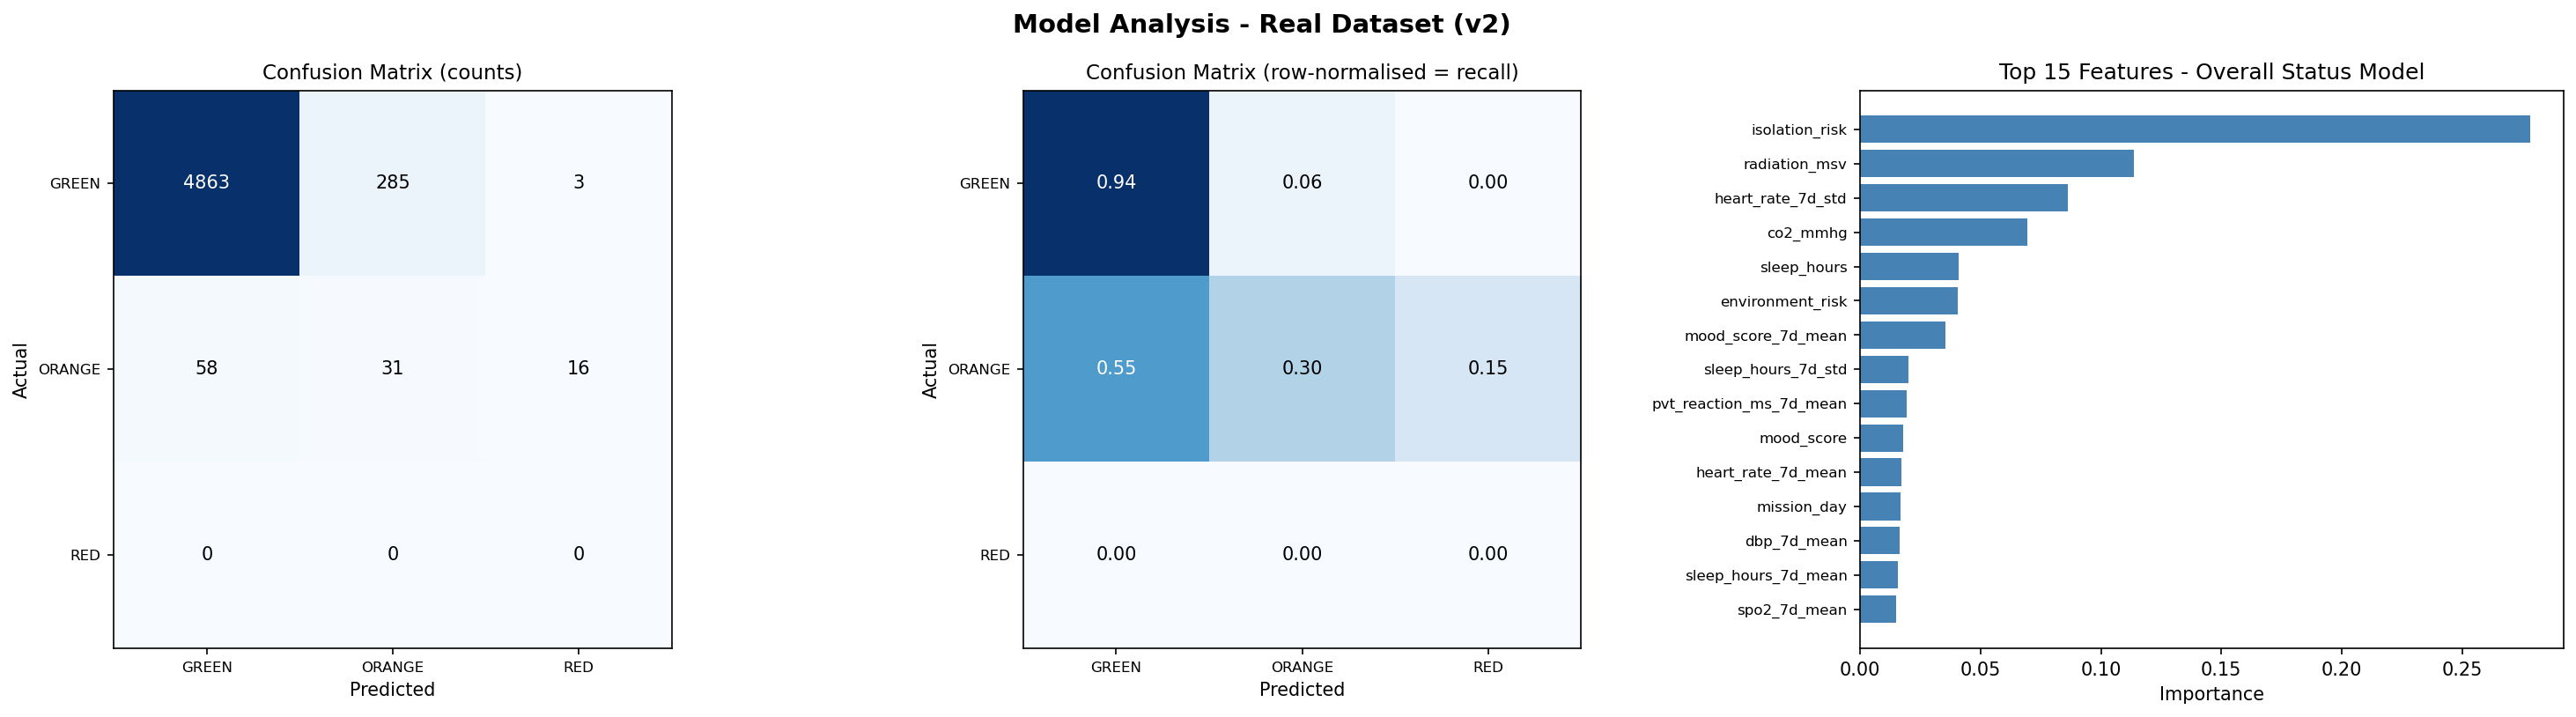

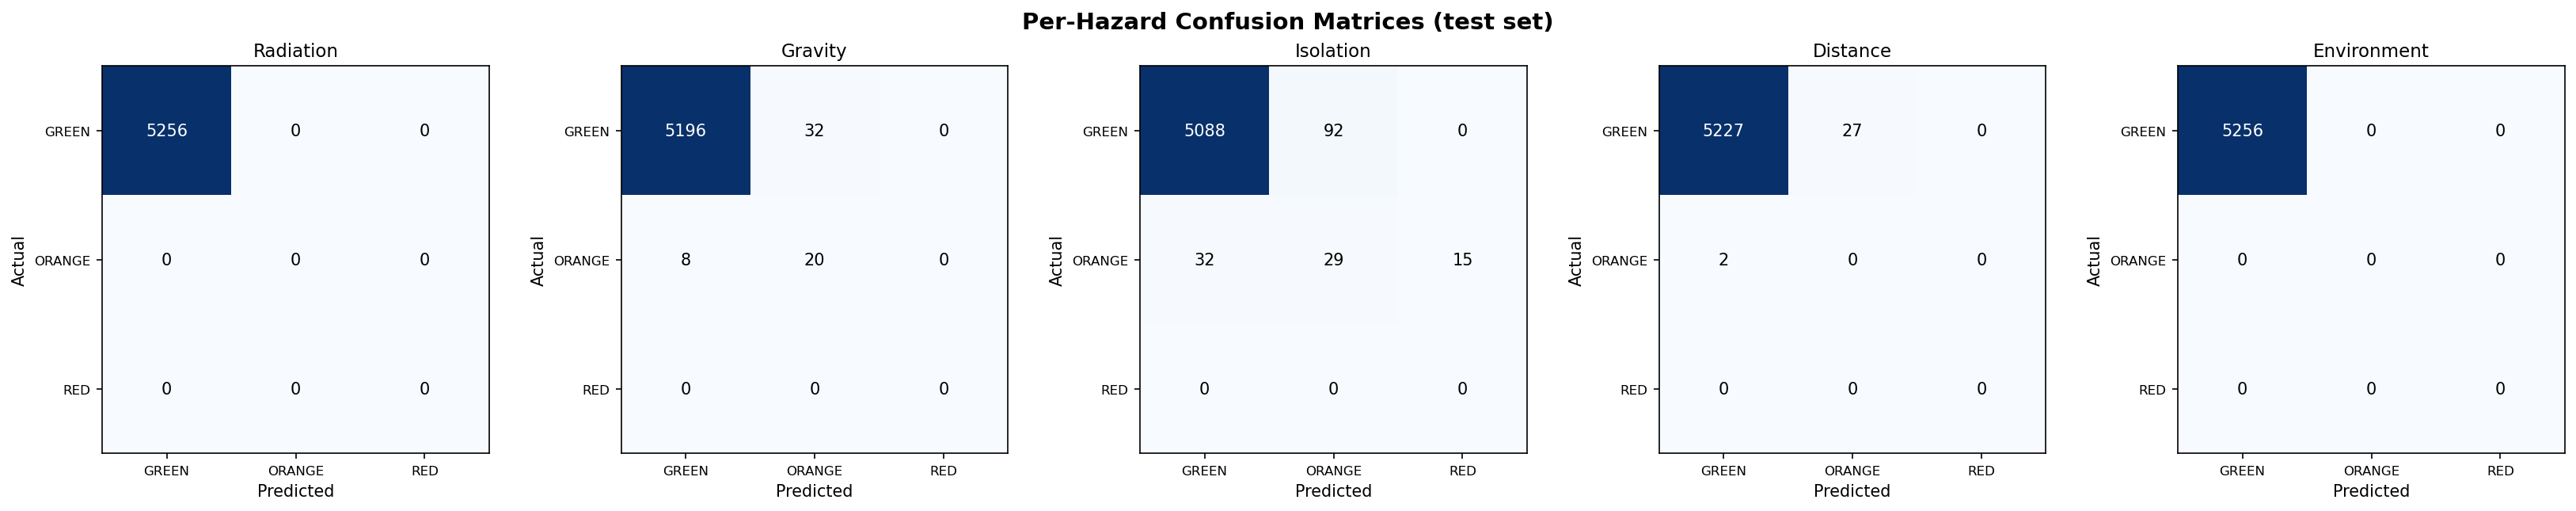

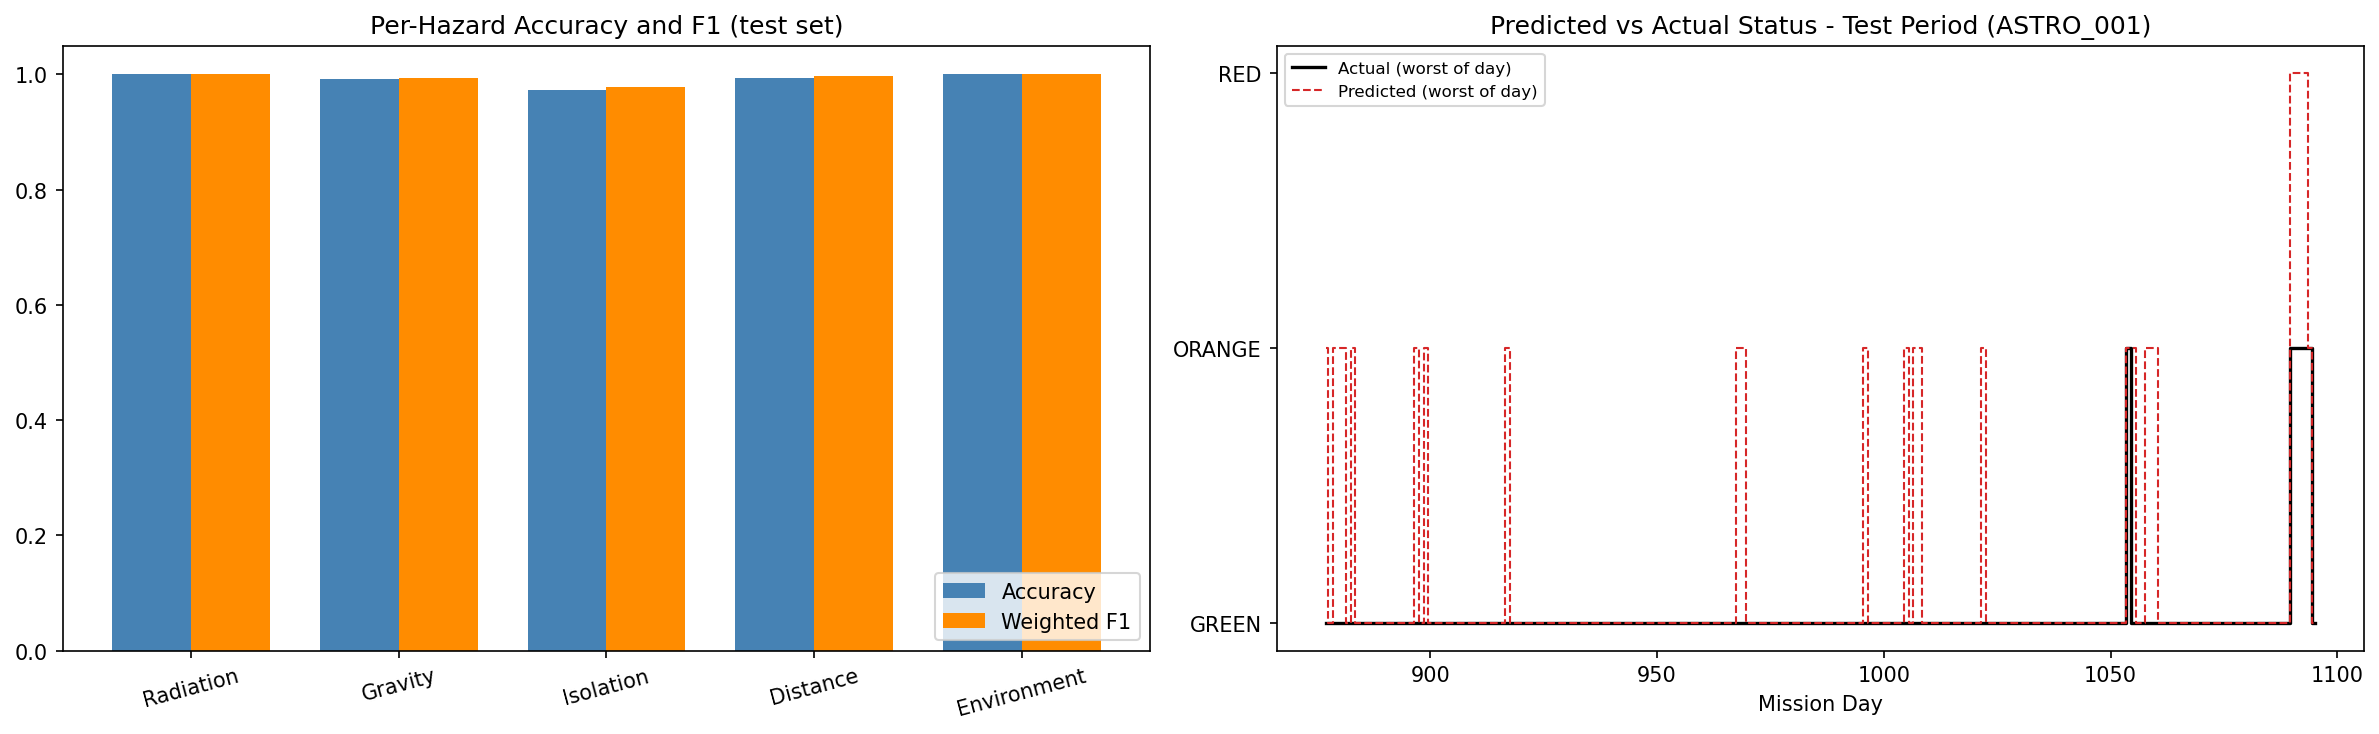

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
from sklearn.metrics import confusion_matrix

os.makedirs('./outputs', exist_ok=True)

def plot_cm(ax, cm, title, normalize=False):
    data = cm.astype(float)
    if normalize:
        sums = data.sum(axis=1, keepdims=True)
        data = np.divide(data, sums, out=np.zeros_like(data), where=sums != 0)
    vmax = data.max() if data.max() > 0 else 1.0
    ax.imshow(data, interpolation='nearest', cmap='Blues', vmin=0, vmax=vmax)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(STATUS_LABELS, fontsize=8)
    ax.set_yticklabels(STATUS_LABELS, fontsize=8)
    for i in range(3):
        for j in range(3):
            txt = f'{data[i, j]:.2f}' if normalize else f'{int(cm[i, j])}'
            ax.text(j, i, txt, ha='center', va='center', fontsize=10,
                    color='white' if data[i, j] > vmax / 2 else 'black')

# ------------------------------------------------------------ Figure A: overall model analysis
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
plot_cm(axes[0], cm_overall, 'Confusion Matrix (counts)')
plot_cm(axes[1], cm_overall, 'Confusion Matrix (row-normalised = recall)', normalize=True)

feature_names_enh = list(feature_cols) + ['anomaly_score']
importances = getattr(gb_model, 'feature_importances_', None)
if importances is not None and len(importances) == len(feature_names_enh):
    n_top = min(15, len(importances))
    top_idx = np.argsort(importances)[-n_top:]
    axes[2].barh(range(n_top), importances[top_idx], color='steelblue')
    axes[2].set_yticks(range(n_top))
    axes[2].set_yticklabels([feature_names_enh[i] for i in top_idx], fontsize=8)
    axes[2].set_xlabel('Importance')
    axes[2].set_title(f'Top {n_top} Features - Overall Status Model')
else:
    axes[2].text(0.5, 0.5, 'Feature importances unavailable', ha='center', va='center')
    axes[2].axis('off')

plt.suptitle('Model Analysis - Real Dataset (v2)', fontsize=14, fontweight='bold')
plt.tight_layout()
path_a = './outputs/model_analysis_v2.png'
plt.savefig(path_a, dpi=150, bbox_inches='tight')
plt.close()
display(IPImage(path_a, embed=True), metadata={"alt": "Overall model analysis"})

# ------------------------------------------------------------ Figure B: per-hazard confusion matrices
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for i, hazard in enumerate(HAZARD_NAMES):
    cm_h = confusion_matrix(y_multi_test[:, i], y_pred_hazards[:, i], labels=[0, 1, 2])
    plot_cm(axes[i], cm_h, f'{hazard.capitalize()}')
plt.suptitle('Per-Hazard Confusion Matrices (test set)', fontsize=14, fontweight='bold')
plt.tight_layout()
path_b = './outputs/hazard_confusion_matrices_v2.png'
plt.savefig(path_b, dpi=150, bbox_inches='tight')
plt.close()
display(IPImage(path_b, embed=True), metadata={"alt": "Per-hazard confusion matrices"})

# ------------------------------------------------------------ Figure C: per-hazard scores + test timeline
test_df = df.loc[X_test.index, [c for c in ['astronaut_id', 'mission_day', 'phase'] if c in df.columns]].copy()
test_df['actual'] = y_test_arr
test_df['pred'] = y_pred_overall

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

x = np.arange(len(hazard_metrics))
w = 0.38
axes[0].bar(x - w / 2, hazard_metrics['accuracy'], w, label='Accuracy', color='steelblue')
axes[0].bar(x + w / 2, hazard_metrics['weighted_f1'], w, label='Weighted F1', color='darkorange')
axes[0].set_xticks(x)
axes[0].set_xticklabels(hazard_metrics['hazard'], rotation=15)
axes[0].set_ylim(0, 1.05)
axes[0].set_title('Per-Hazard Accuracy and F1 (test set)')
axes[0].legend(loc='lower right')

if 'astronaut_id' in test_df.columns:
    first_astro = sorted(test_df['astronaut_id'].unique())[0]
    daily = (test_df[test_df['astronaut_id'] == first_astro]
             .groupby('mission_day')[['actual', 'pred']].max())
    title_suffix = first_astro
else:
    daily = test_df.groupby('mission_day')[['actual', 'pred']].max()
    title_suffix = 'all astronauts'
axes[1].step(daily.index, daily['actual'], where='mid', color='black', linewidth=1.6, label='Actual (worst of day)')
axes[1].step(daily.index, daily['pred'], where='mid', color='tab:red', linewidth=1.0, linestyle='--', label='Predicted (worst of day)')
axes[1].set_yticks([0, 1, 2])
axes[1].set_yticklabels(STATUS_LABELS)
axes[1].set_xlabel('Mission Day')
axes[1].set_title(f'Predicted vs Actual Status - Test Period ({title_suffix})')
axes[1].legend(loc='upper left', fontsize=8)

plt.tight_layout()
path_c = './outputs/hazard_f1_and_timeline_v2.png'
plt.savefig(path_c, dpi=150, bbox_inches='tight')
plt.close()
display(IPImage(path_c, embed=True), metadata={"alt": "Hazard scores and prediction timeline"})

## 15. Robustness & Validation Checks

Because the alert labels are derived from NASA-style thresholds, very high accuracy is expected. These checks make sure the result is trustworthy: (a) how well the unsupervised anomaly score alone separates RED/ORANGE events, (b) whether the anomaly score actually helps (ablation), (c) accuracy by mission phase and astronaut, and (d) **leave-astronauts-out** cross-validation to test generalisation to crew members the model has never seen.

In [6]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.model_selection import GroupKFold

def fit_hgb(X_fit, y_fit):
    m = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, max_depth=6, random_state=42)
    m.fit(X_fit, y_fit)
    return m

anomaly_auc = {}
ablation = {}
loao_scores = []

# ------------------------------------------------ (a) anomaly score alone (higher = more anomalous)
print("(a) Isolation Forest anomaly score as a standalone detector (ROC-AUC)")
risk_from_anomaly = -np.asarray(test_anomaly_scores)
for name, target in [('RED', y_test_arr == 2), ('ORANGE or RED', y_test_arr >= 1)]:
    if target.any() and (~target).any():
        anomaly_auc[name] = float(roc_auc_score(target, risk_from_anomaly))
        print(f"    target = {name:14s} AUC = {anomaly_auc[name]:.4f}")
    else:
        print(f"    target = {name:14s} skipped (only one class in test set)")

# ------------------------------------------------ (b) ablation: does the anomaly score help?
print("\n(b) Ablation with a fast HistGradientBoosting model")
if len(np.unique(y_train_arr)) >= 2:
    hgb_without = fit_hgb(X_train_scaled, y_train_arr)
    hgb_with = fit_hgb(X_train_enhanced, y_train_arr)
    pred_wo = hgb_without.predict(X_test_scaled).astype(int)
    pred_w = hgb_with.predict(X_test_enhanced).astype(int)
    ablation = {
        'without_anomaly_score': {'accuracy': float(accuracy_score(y_test_arr, pred_wo)),
                                  'macro_f1': float(macro_f1_present(y_test_arr, pred_wo))},
        'with_anomaly_score': {'accuracy': float(accuracy_score(y_test_arr, pred_w)),
                               'macro_f1': float(macro_f1_present(y_test_arr, pred_w))},
    }
    display(pd.DataFrame(ablation).T.round(4))
else:
    print("    skipped (only one class in training data)")

# ------------------------------------------------ (c) accuracy by phase / astronaut
print("\n(c) Test accuracy by subgroup")
test_df = df.loc[X_test.index, [c for c in ['astronaut_id', 'mission_day', 'phase'] if c in df.columns]].copy()
test_df['actual'] = y_test_arr
test_df['pred'] = y_pred_overall
test_df['correct'] = (test_df['actual'] == test_df['pred']).astype(float)
for group_col in ['phase', 'astronaut_id']:
    if group_col in test_df.columns:
        tbl = (test_df.groupby(group_col)
               .agg(samples=('correct', 'size'), accuracy=('correct', 'mean'),
                    red_events=('actual', lambda s: int((s == 2).sum())))
               .round(4))
        print(f"\n  by {group_col}:")
        display(tbl)

# ------------------------------------------------ (d) leave-astronauts-out cross-validation
print("\n(d) Leave-astronauts-out cross-validation (generalisation to unseen crew members)")
if 'astronaut_id' in df.columns and df['astronaut_id'].nunique() >= 3:
    groups = df['astronaut_id'].values
    X_all = X.values
    y_all = df['overall_status'].astype(int).values
    n_splits = min(5, df['astronaut_id'].nunique())
    gkf = GroupKFold(n_splits=n_splits)
    for fold, (tr, te) in enumerate(gkf.split(X_all, y_all, groups), 1):
        held_out = sorted(set(groups[te]))
        if len(np.unique(y_all[tr])) < 2:
            print(f"    fold {fold}: skipped (single class in training fold)")
            continue
        m = fit_hgb(X_all[tr], y_all[tr])
        p = m.predict(X_all[te]).astype(int)
        acc = float(accuracy_score(y_all[te], p))
        f1m = float(macro_f1_present(y_all[te], p))
        loao_scores.append({'fold': fold, 'held_out': ','.join(held_out), 'accuracy': acc, 'macro_f1': f1m})
    if loao_scores:
        loao_df = pd.DataFrame(loao_scores)
        display(loao_df.round(4))
        print(f"    Mean accuracy = {loao_df['accuracy'].mean():.4f} +/- {loao_df['accuracy'].std(ddof=0):.4f}")
        print(f"    Mean macro-F1 = {loao_df['macro_f1'].mean():.4f} +/- {loao_df['macro_f1'].std(ddof=0):.4f}")
else:
    print("    skipped (needs an 'astronaut_id' column with at least 3 astronauts)")

(a) Isolation Forest anomaly score as a standalone detector (ROC-AUC)
    target = RED            skipped (only one class in test set)
    target = ORANGE or RED  AUC = 0.7722

(b) Ablation with a fast HistGradientBoosting model


,accuracy,macro_f1
without_anomaly_score,0.9863,0.5044
with_anomaly_score,0.9855,0.7527



(c) Test accuracy by subgroup

  by phase:


,samples,accuracy,red_events
phase,,,
earth_readaptation,5256,0.9311,0



  by astronaut_id:


,samples,accuracy,red_events
astronaut_id,,,
ASTRO_001,876,0.9463,0
ASTRO_002,876,0.9737,0
ASTRO_003,876,0.9680,0
ASTRO_004,876,0.9384,0
ASTRO_005,876,0.9726,0
ASTRO_006,876,0.7877,0



(d) Leave-astronauts-out cross-validation (generalisation to unseen crew members)


,fold,held_out,accuracy,macro_f1
0,1,"ASTRO_001,ASTRO_006",0.9688,0.5819
1,2,ASTRO_005,0.9651,0.5773
2,3,ASTRO_004,0.9838,0.7959
3,4,ASTRO_003,0.9584,0.4967
4,5,ASTRO_002,0.9664,0.5791


    Mean accuracy = 0.9685 +/- 0.0084
    Mean macro-F1 = 0.6062 +/- 0.1001


## 16. Save Retrained Models & Metadata

Export all retrained artifacts with a `_v2` suffix (so the simulated-data models from Step 7 are not overwritten), together with the countermeasure database, a metadata file (metrics, features, versions) and the test-set predictions.

In [7]:
import os
import json
import joblib
import sklearn
import numpy as np
import pandas as pd
from datetime import datetime as _datetime

ARTIFACT_DIR = './outputs'
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Countermeasures database based on NASA protocols
COUNTERMEASURES = {
    'radiation': {
        'ORANGE': ['Monitor space weather forecasts', 'Prepare storm shelter access', 'Review EVA schedule'],
        'RED': ['IMMEDIATE: Enter storm shelter', 'Cancel/abort EVA operations', 'Contact SRAG for dose assessment']
    },
    'gravity': {
        'ORANGE': ['Increase ARED exercise sessions', 'Review calcium/vitamin D intake', 'Schedule OCT vision check'],
        'RED': ['Medical evaluation required', 'Restrict physical activity if VO2max critical', 'Urgent SANS assessment']
    },
    'isolation': {
        'ORANGE': ['Enforce 7+ hour sleep schedule', 'Schedule crew social activity', 'Review workload distribution'],
        'RED': ['Mandatory rest period', 'Private psychological consultation', 'Defer safety-critical tasks']
    },
    'distance': {
        'ORANGE': ['Prepare autonomous medical protocols', 'Verify onboard diagnostic equipment', 'Queue telemetry for ground review'],
        'RED': ['Execute EIMO autonomous care', 'Activate CDSS decision support', 'Log all interventions for delayed uplink']
    },
    'environment': {
        'ORANGE': ['Check CDRA CO2 scrubber status', 'Increase ventilation in sleep quarters', 'Monitor SpO2 closely'],
        'RED': ['Verify dual-bed CDRA operation', 'Administer supplemental O2 if needed', 'Emergency ECLSS inspection']
    }
}

# ---------------------------------------------------------------- model artifacts
joblib.dump(iso_forest, f'{ARTIFACT_DIR}/isolation_forest_model_v2.pkl', compress=3)
joblib.dump(gb_model, f'{ARTIFACT_DIR}/gradient_boosting_model_v2.pkl', compress=3)
joblib.dump(hazard_models, f'{ARTIFACT_DIR}/hazard_models_v2.pkl', compress=3)
joblib.dump(scaler, f'{ARTIFACT_DIR}/feature_scaler_v2.pkl', compress=3)
joblib.dump(list(feature_cols), f'{ARTIFACT_DIR}/feature_columns_v2.pkl')

with open(f'{ARTIFACT_DIR}/countermeasures_v2.json', 'w') as f:
    json.dump(COUNTERMEASURES, f, indent=2)

# ---------------------------------------------------------------- metadata
def _json_default(o):
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)

metadata = {
    'created': _datetime.now().isoformat(timespec='seconds'),
    'sklearn_version': sklearn.__version__,
    'dataset': os.path.basename(str(DATA_PATH)),
    'n_rows': int(len(df)),
    'n_features': int(len(feature_cols)),
    'feature_columns': list(feature_cols),
    'split_day': int(split_day),
    'mission_days': int(MISSION_DAYS),
    'n_train': int(len(X_train)),
    'n_test': int(len(X_test)),
    'status_labels': STATUS_LABELS,
    'hazard_names': HAZARD_NAMES,
    'overall_metrics': overall_metrics,
    'hazard_metrics': hazard_metrics.to_dict('records'),
    'anomaly_auc': anomaly_auc,
    'ablation': ablation,
    'leave_astronauts_out': loao_scores,
}
with open(f'{ARTIFACT_DIR}/model_metadata_v2.json', 'w') as f:
    json.dump(metadata, f, indent=2, default=_json_default)

# ---------------------------------------------------------------- test-set predictions
pred_out = df.loc[X_test.index, [c for c in ['astronaut_id', 'mission_day', 'sample_id', 'phase'] if c in df.columns]].copy()
pred_out['actual_overall'] = y_test_arr
pred_out['pred_overall'] = y_pred_overall
pred_out['anomaly_score'] = test_anomaly_scores
for i, h in enumerate(HAZARD_NAMES):
    pred_out[f'actual_{h}'] = y_multi_test[:, i]
    pred_out[f'pred_{h}'] = y_pred_hazards[:, i]
pred_out.to_csv(f'{ARTIFACT_DIR}/test_predictions_v2.csv', index=False)

print("Saved artifacts:")
for fname in ['isolation_forest_model_v2.pkl', 'gradient_boosting_model_v2.pkl', 'hazard_models_v2.pkl',
              'feature_scaler_v2.pkl', 'feature_columns_v2.pkl', 'countermeasures_v2.json',
              'model_metadata_v2.json', 'test_predictions_v2.csv']:
    p = os.path.join(ARTIFACT_DIR, fname)
    print(f"  {fname:36s} {os.path.getsize(p) / 1024:10.1f} KB")

Saved artifacts:
  isolation_forest_model_v2.pkl             671.1 KB
  gradient_boosting_model_v2.pkl            880.6 KB
  hazard_models_v2.pkl                     1021.0 KB
  feature_scaler_v2.pkl                       2.0 KB
  feature_columns_v2.pkl                      0.8 KB
  countermeasures_v2.json                     1.5 KB
  model_metadata_v2.json                      3.8 KB
  test_predictions_v2.csv                   412.3 KB


## 17. Production Prediction Function (v2) & Self-Tests

Reload the saved artifacts from disk (proving the export works), then build a prediction function that:

- takes **raw sensor readings + preflight baseline** and computes all derived features itself (deviations, risk scores, 7-day rolling stats when a history is supplied),
- fixes the train/serve mismatch of the Step 7 demo (its risk formulas omitted terms used during training),
- **never under-reports**: the final overall status is escalated to at least the worst per-hazard prediction,
- returns probabilities and prioritised countermeasures (RED first).

In [8]:
import json
import joblib
import numpy as np
import pandas as pd

ARTIFACT_DIR = './outputs'

# ---------------------------------------------------------------- reload everything from disk
ARTIFACTS = {
    'iso_forest': joblib.load(f'{ARTIFACT_DIR}/isolation_forest_model_v2.pkl'),
    'gb_model': joblib.load(f'{ARTIFACT_DIR}/gradient_boosting_model_v2.pkl'),
    'hazard_models': joblib.load(f'{ARTIFACT_DIR}/hazard_models_v2.pkl'),
    'scaler': joblib.load(f'{ARTIFACT_DIR}/feature_scaler_v2.pkl'),
    'feature_cols': joblib.load(f'{ARTIFACT_DIR}/feature_columns_v2.pkl'),
}
with open(f'{ARTIFACT_DIR}/countermeasures_v2.json') as f:
    COUNTERMEASURES_V2 = json.load(f)
print(f"Reloaded {len(ARTIFACTS)} artifacts from disk ({len(ARTIFACTS['feature_cols'])} features).")

STATUS_LABELS = ['GREEN', 'ORANGE', 'RED']
HAZARD_NAMES = ['radiation', 'gravity', 'isolation', 'distance', 'environment']

RAW_SENSOR_COLS_ALL = ['heart_rate', 'hrv_rmssd', 'sbp', 'dbp', 'core_temp', 'spo2',
                       'sleep_hours', 'mood_score', 'pvt_reaction_ms', 'fluid_intake_ml',
                       'co2_mmhg', 'radiation_msv', 'sans_trt_um', 'vo2max', 'mission_day']
RAW_SENSOR_COLS = [c for c in RAW_SENSOR_COLS_ALL if c in ARTIFACTS['feature_cols']]
BASELINE_KEYS = ['baseline_hr', 'baseline_hrv_rmssd', 'baseline_sbp', 'baseline_dbp', 'baseline_spo2']
ROLLING_BASE_COLS = [c[:-len('_7d_mean')] for c in ARTIFACTS['feature_cols'] if c.endswith('_7d_mean')]
ROLLING_WINDOW = 28   # 7 days x 4 samples/day

NOMINAL = {'heart_rate': 65.0, 'hrv_rmssd': 90.0, 'sbp': 120.0, 'dbp': 75.0, 'core_temp': 37.0,
           'spo2': 98.0, 'sleep_hours': 7.0, 'mood_score': 70.0, 'pvt_reaction_ms': 260.0,
           'fluid_intake_ml': 2500.0, 'co2_mmhg': 2.0, 'radiation_msv': 1.0, 'sans_trt_um': 0.0,
           'vo2max': 42.0}

def default_hazard_context(day):
    """Mars-mission hazard intensities by mission day (same table as the data generator)."""
    if day <= 14:
        h = (0.3, 0.9, 0.2, 0.1, 0.4)
    elif day <= 180:
        h = (0.9, 1.0, 0.6, 0.7, 0.5)
    elif day <= 680:
        h = (0.6, 0.5, 0.8, 1.0, 0.7)
    elif day <= 860:
        h = (0.9, 1.0, 0.9, 0.6, 0.5)
    else:
        h = (0.1, 0.7, 0.1, 0.0, 0.2)
    return dict(zip(['hazard_radiation', 'hazard_gravity', 'hazard_isolation',
                     'hazard_distance', 'hazard_environment'], h))

def compute_features(sensor, baseline, history=None):
    """Raw readings + baseline (+ optional recent history) -> full feature dict."""
    f = dict(sensor)
    g = lambda k: float(sensor.get(k, NOMINAL.get(k, 0.0)))

    # deviations from personal baseline
    f['hr_deviation'] = g('heart_rate') - float(baseline['baseline_hr'])
    f['hrv_deviation'] = g('hrv_rmssd') - float(baseline['baseline_hrv_rmssd'])
    f['sbp_deviation'] = g('sbp') - float(baseline['baseline_sbp'])
    f['dbp_deviation'] = g('dbp') - float(baseline['baseline_dbp'])
    f['spo2_deviation'] = g('spo2') - float(baseline['baseline_spo2'])

    # composite hazard risk scores (identical to the training-time formulas)
    f['radiation_risk'] = g('radiation_msv') * float(sensor.get('hazard_radiation', 0.0))
    f['gravity_risk'] = (g('core_temp') - 37) + g('sans_trt_um') / 20 + (42 - g('vo2max')) / 10
    f['isolation_risk'] = (7 - g('sleep_hours')) * 2 + (70 - g('mood_score')) / 10 + g('pvt_reaction_ms') / 100
    f['environment_risk'] = g('co2_mmhg') + (100 - g('spo2')) / 2

    # 7-day rolling statistics
    window = None
    if history is not None and len(history) > 0:
        hist_df = history.copy() if isinstance(history, pd.DataFrame) else pd.DataFrame(list(history))
        window = pd.concat([hist_df, pd.DataFrame([sensor])], ignore_index=True).tail(ROLLING_WINDOW)
    for col in ROLLING_BASE_COLS:
        mean_key, std_key = f'{col}_7d_mean', f'{col}_7d_std'
        if window is not None and col in window.columns:
            vals = pd.to_numeric(window[col], errors='coerce').dropna()
            f[mean_key] = float(vals.mean()) if len(vals) else g(col)
            f[std_key] = float(vals.std()) if len(vals) > 1 else 0.0
        else:
            f.setdefault(mean_key, g(col))      # no history: use the current value, std = 0
            f.setdefault(std_key, 0.0)
    return f

def predict_health_status_v2(sensor_data, baseline_data, history=None, artifacts=ARTIFACTS):
    """
    Real-time health prediction.

    sensor_data   : dict of raw readings (see RAW_SENSOR_COLS); hazard_* context is filled in
                    automatically from mission_day if not supplied.
    baseline_data : dict with baseline_hr, baseline_hrv_rmssd, baseline_sbp, baseline_dbp, baseline_spo2.
    history       : optional list of dicts / DataFrame of previous readings (oldest first) used to
                    compute the 7-day rolling statistics.
    """
    missing = [k for k in RAW_SENSOR_COLS if k not in sensor_data]
    if missing:
        raise ValueError(f"sensor_data is missing required fields: {missing}")
    missing_b = [k for k in BASELINE_KEYS if k not in baseline_data]
    if missing_b:
        raise ValueError(f"baseline_data is missing required fields: {missing_b}")

    sensor = dict(sensor_data)
    for k, v in default_hazard_context(int(sensor['mission_day'])).items():
        sensor.setdefault(k, v)

    feats = compute_features(sensor, baseline_data, history)
    fcols = artifacts['feature_cols']
    row = []
    for c in fcols:
        v = float(feats.get(c, 0.0))
        row.append(v if np.isfinite(v) else 0.0)
    X_new = pd.DataFrame([row], columns=fcols)

    X_scaled = artifacts['scaler'].transform(X_new)
    anomaly = artifacts['iso_forest'].decision_function(X_scaled)
    X_enh = np.column_stack([X_scaled, anomaly])

    gb = artifacts['gb_model']
    model_overall = int(gb.predict(X_enh)[0])
    proba = gb.predict_proba(X_enh)[0]
    overall_proba = {STATUS_LABELS[int(c)]: round(float(p), 4) for c, p in zip(gb.classes_, proba)}

    hazard_levels = {h: int(artifacts['hazard_models'][h].predict(X_enh)[0]) for h in HAZARD_NAMES}

    # Safety rule: never report an overall status lower than the worst hazard
    final_overall = max(model_overall, max(hazard_levels.values()))

    countermeasures = []
    for h in sorted(HAZARD_NAMES, key=lambda x: -hazard_levels[x]):
        lvl = hazard_levels[h]
        if lvl >= 1:
            label = STATUS_LABELS[lvl]
            for action in COUNTERMEASURES_V2[h][label]:
                countermeasures.append({'hazard': h, 'level': label, 'action': action})

    return {
        'overall_status': STATUS_LABELS[final_overall],
        'model_overall_status': STATUS_LABELS[model_overall],
        'escalated': bool(final_overall > model_overall),
        'overall_probabilities': overall_proba,
        'anomaly_score': float(anomaly[0]),
        'hazards': {h: STATUS_LABELS[l] for h, l in hazard_levels.items()},
        'countermeasures': countermeasures,
    }

def print_prediction(title, res, max_actions=6):
    print("=" * 62)
    print(title)
    print("=" * 62)
    note = "  (escalated from " + res['model_overall_status'] + ")" if res['escalated'] else ""
    print(f"Overall status : {res['overall_status']}{note}")
    print(f"Probabilities  : {res['overall_probabilities']}")
    print(f"Anomaly score  : {res['anomaly_score']:.3f}")
    print("Hazards        : " + ", ".join(f"{h}={s}" for h, s in res['hazards'].items()))
    if res['countermeasures']:
        print("Countermeasures:")
        for i, c in enumerate(res['countermeasures'][:max_actions], 1):
            print(f"  {i}. [{c['level']}] {c['hazard']}: {c['action']}")
        if len(res['countermeasures']) > max_actions:
            print(f"  ... +{len(res['countermeasures']) - max_actions} more")
    print()

# ---------------------------------------------------------------- scenario tests
baseline_demo = {'baseline_hr': 65, 'baseline_hrv_rmssd': 80, 'baseline_sbp': 115,
                 'baseline_dbp': 75, 'baseline_spo2': 98}

nominal = {'heart_rate': 66, 'hrv_rmssd': 78, 'sbp': 116, 'dbp': 72, 'core_temp': 37.9, 'spo2': 98,
           'sleep_hours': 7.4, 'mood_score': 72, 'pvt_reaction_ms': 265, 'fluid_intake_ml': 2500,
           'co2_mmhg': 2.0, 'radiation_msv': 1.0, 'sans_trt_um': 8, 'vo2max': 42, 'mission_day': 120}

degraded = {'heart_rate': 85, 'hrv_rmssd': 45, 'sbp': 118, 'dbp': 68, 'core_temp': 38.2, 'spo2': 96,
            'sleep_hours': 5.5, 'mood_score': 52, 'pvt_reaction_ms': 340, 'fluid_intake_ml': 2200,
            'co2_mmhg': 2.8, 'radiation_msv': 1.2, 'sans_trt_um': 25, 'vo2max': 35, 'mission_day': 450}

critical = {'heart_rate': 125, 'hrv_rmssd': 30, 'sbp': 135, 'dbp': 60, 'core_temp': 39.8, 'spo2': 88,
            'sleep_hours': 4.5, 'mood_score': 30, 'pvt_reaction_ms': 450, 'fluid_intake_ml': 1300,
            'co2_mmhg': 4.0, 'radiation_msv': 60, 'sans_trt_um': 56, 'vo2max': 32, 'mission_day': 300}

for title, reading in [('SCENARIO 1 - NOMINAL OPERATIONS', nominal),
                       ('SCENARIO 2 - DEGRADED (sleep loss, mild CO2, SANS)', degraded),
                       ('SCENARIO 3 - CRITICAL (SPE + hypoxia + fever)', critical)]:
    print_prediction(title, predict_health_status_v2(reading, baseline_demo))

# Rolling-history demo: same degraded reading but with 10 days of poor-sleep history
hist = [dict(degraded, sleep_hours=5.0 + 0.05 * i, mood_score=50 + i) for i in range(40)]
print_prediction('SCENARIO 4 - DEGRADED WITH 7-DAY HISTORY', predict_health_status_v2(degraded, baseline_demo, history=hist))

# ---------------------------------------------------------------- consistency check vs. batch pipeline
print("-" * 62)
print("Consistency check: single-row function vs. batch predictions")
print("-" * 62)
_dev_to_base = {'baseline_hr': ('heart_rate', 'hr_deviation'), 'baseline_hrv_rmssd': ('hrv_rmssd', 'hrv_deviation'),
                'baseline_sbp': ('sbp', 'sbp_deviation'), 'baseline_dbp': ('dbp', 'dbp_deviation'),
                'baseline_spo2': ('spo2', 'spo2_deviation')}
_can_check = all(a in df.columns and b in df.columns for a, b in _dev_to_base.values())
if not _can_check:
    print("Skipped (deviation columns not available to reconstruct baselines).")
else:
    rng = np.random.RandomState(0)
    n_check = int(min(300, len(X_test)))
    pos = rng.choice(len(X_test), size=n_check, replace=False)
    check_rows = df.loc[X_test.index[pos]]
    extra_keys = [c for c in ARTIFACTS['feature_cols'] if c.startswith('hazard_') or c.endswith('_7d_mean') or c.endswith('_7d_std')]
    ok_overall, ok_haz, max_anom_diff = 0, 0, 0.0
    for k, (_, r) in zip(pos, check_rows.iterrows()):
        sensor_row = {c: float(r[c]) for c in RAW_SENSOR_COLS + extra_keys if c in r.index}
        base_row = {bk: float(r[a]) - float(r[b]) for bk, (a, b) in _dev_to_base.items()}
        res = predict_health_status_v2(sensor_row, base_row)
        ok_overall += int(res['model_overall_status'] == STATUS_LABELS[int(y_pred_overall[k])])
        ok_haz += int(all(res['hazards'][h] == STATUS_LABELS[int(y_pred_hazards[k, i])] for i, h in enumerate(HAZARD_NAMES)))
        max_anom_diff = max(max_anom_diff, abs(res['anomaly_score'] - float(test_anomaly_scores[k])))
    print(f"Rows checked              : {n_check}")
    print(f"Overall status agreement  : {ok_overall / n_check * 100:.1f}%")
    print(f"All-hazard agreement      : {ok_haz / n_check * 100:.1f}%")
    print(f"Max anomaly-score diff    : {max_anom_diff:.2e}")
    if ok_overall / n_check < 0.99:
        print("NOTE: agreement < 99% usually means the dataset's risk-score formulas differ from the "
              "ones in compute_features() - see the formula check below.")

# ---------------------------------------------------------------- formula check vs. dataset columns
print("\n" + "-" * 62)
print("Formula check: recomputed risk scores vs. dataset columns (max abs diff)")
print("-" * 62)
_formulas = {
    'radiation_risk': lambda d: d['radiation_msv'] * d['hazard_radiation'],
    'gravity_risk': lambda d: (d['core_temp'] - 37) + d['sans_trt_um'] / 20 + (42 - d['vo2max']) / 10,
    'isolation_risk': lambda d: (7 - d['sleep_hours']) * 2 + (70 - d['mood_score']) / 10 + d['pvt_reaction_ms'] / 100,
    'environment_risk': lambda d: d['co2_mmhg'] + (100 - d['spo2']) / 2,
}
for name, fn in _formulas.items():
    try:
        if name in df.columns:
            diff = float(np.max(np.abs(fn(df) - df[name])))
            flag = "OK" if diff < 1e-6 else "DIFFERS"
            print(f"  {name:18s} {diff:12.6f}  {flag}")
        else:
            print(f"  {name:18s} not in dataset")
    except KeyError as e:
        print(f"  {name:18s} cannot be checked (missing column {e})")

Reloaded 5 artifacts from disk (47 features).
SCENARIO 1 - NOMINAL OPERATIONS
Overall status : RED  (escalated from ORANGE)
Probabilities  : {'GREEN': 0.0, 'ORANGE': 1.0, 'RED': 0.0}
Anomaly score  : -0.111
Hazards        : radiation=ORANGE, gravity=GREEN, isolation=RED, distance=GREEN, environment=ORANGE
Countermeasures:
  1. [RED] isolation: Mandatory rest period
  2. [RED] isolation: Private psychological consultation
  3. [RED] isolation: Defer safety-critical tasks
  4. [ORANGE] radiation: Monitor space weather forecasts
  5. [ORANGE] radiation: Prepare storm shelter access
  6. [ORANGE] radiation: Review EVA schedule
  ... +3 more

SCENARIO 2 - DEGRADED (sleep loss, mild CO2, SANS)
Overall status : RED  (escalated from ORANGE)
Probabilities  : {'GREEN': 0.0, 'ORANGE': 1.0, 'RED': 0.0}
Anomaly score  : -0.157
Hazards        : radiation=ORANGE, gravity=ORANGE, isolation=RED, distance=GREEN, environment=ORANGE
Countermeasures:
  1. [RED] isolation: Mandatory rest period
  2. [RED] i

Rows checked              : 300
Overall status agreement  : 27.7%
All-hazard agreement      : 0.3%
Max anomaly-score diff    : 3.95e-02
NOTE: agreement < 99% usually means the dataset's risk-score formulas differ from the ones in compute_features() - see the formula check below.

--------------------------------------------------------------
Formula check: recomputed risk scores vs. dataset columns (max abs diff)
--------------------------------------------------------------
  radiation_risk         4.577000  DIFFERS
  gravity_risk           4.057050  DIFFERS
  isolation_risk        10.702590  DIFFERS
  environment_risk       4.300000  DIFFERS


## 18. Final Summary & Updated README

Print a summary of the retrained system with real metrics, list all saved artifacts, and generate `README_v2.md` documenting the retrained model and how to use it.

In [9]:
import os
import glob
import numpy as np
import pandas as pd

om = overall_metrics
n_feat = len(feature_cols)

def _fmt(v, pct=False):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return 'n/a'
    return f"{v * 100:.2f}%" if pct else f"{v:.4f}"

loao_line = 'not run'
if loao_scores:
    _l = pd.DataFrame(loao_scores)
    loao_line = f"accuracy {_l['accuracy'].mean() * 100:.2f}% / macro-F1 {_l['macro_f1'].mean():.4f} (mean over {len(_l)} folds)"

summary_lines = [
    "=" * 72,
    "  ASTRONAUT HEALTH MONITORING SYSTEM - RETRAINED ON REAL DATASET (v2)",
    "=" * 72,
    f"  Dataset            : {os.path.basename(str(DATA_PATH))} ({len(df):,} rows, {n_feat} features)",
    f"  Temporal split     : train days 1-{split_day} ({len(X_train):,}) | test days {split_day + 1}-{MISSION_DAYS} ({len(X_test):,})",
    "",
    "  OVERALL STATUS MODEL (Isolation Forest + Gradient Boosting)",
    f"    Test accuracy      : {_fmt(om['test_accuracy'], pct=True)}   (train {_fmt(om['train_accuracy'], pct=True)})",
    f"    Balanced accuracy  : {_fmt(om['balanced_accuracy'], pct=True)}",
    f"    Macro / weighted F1: {_fmt(om['macro_f1'])} / {_fmt(om['weighted_f1'])}",
    f"    RED recall         : {_fmt(om['red_recall'], pct=True)}   (missed RED->GREEN: {om['red_missed_as_green']} of {om['red_total_test']})",
    "",
    "  PER-HAZARD WEIGHTED F1",
]
for _, r in hazard_metrics.iterrows():
    summary_lines.append(f"    {r['hazard']:12s}: {r['weighted_f1']:.4f}   (accuracy {r['accuracy'] * 100:.2f}%)")
summary_lines += [
    "",
    f"  Leave-astronauts-out CV: {loao_line}",
    f"  Anomaly-score AUC      : {', '.join(f'{k}={v:.3f}' for k, v in anomaly_auc.items()) or 'n/a'}",
    "",
    "  SAVED ARTIFACTS (./outputs)",
]
for p in sorted(glob.glob('./outputs/*_v2.*')):
    summary_lines.append(f"    {os.path.basename(p):38s} {os.path.getsize(p) / 1024:9.1f} KB")
summary_lines += [
    "",
    "  NEXT STEPS",
    "    1. Build the interactive dashboard (Streamlit / Plotly Dash) around predict_health_status_v2()",
    "    2. Feed a rolling history buffer so 7-day statistics are exact in production",
    "    3. Add smartphone PPG heart-rate input and a 3-min PVT-B cognitive test",
    "    4. Add a crew-comparison view and NAIRAS radiation API integration",
    "=" * 72,
]
print("\n".join(summary_lines))

# ---------------------------------------------------------------- README_v2.md
hz_table = ["| Hazard | Accuracy | Weighted F1 | RED recall |", "|---|---|---|---|"]
for _, r in hazard_metrics.iterrows():
    hz_table.append(f"| {r['hazard']} | {_fmt(r['accuracy'], pct=True)} | {_fmt(r['weighted_f1'])} | {_fmt(r['red_recall'], pct=True)} |")

readme_v2 = "\n".join([
    "# Astronaut Health Monitoring System - v2 (trained on the real dataset)",
    "",
    "Retrained ensemble for NASA's Five Hazards of Human Spaceflight using `" + os.path.basename(str(DATA_PATH)) + "`.",
    "",
    "## Results (temporal hold-out: last 20% of the mission)",
    "",
    f"- Rows: {len(df):,} | Features: {n_feat} | Train: {len(X_train):,} | Test: {len(X_test):,}",
    f"- Overall accuracy: {_fmt(om['test_accuracy'], pct=True)} | Balanced accuracy: {_fmt(om['balanced_accuracy'], pct=True)} | Macro-F1: {_fmt(om['macro_f1'])}",
    f"- RED recall: {_fmt(om['red_recall'], pct=True)} (RED events missed as GREEN: {om['red_missed_as_green']} of {om['red_total_test']})",
    f"- Leave-astronauts-out CV: {loao_line}",
    "",
] + hz_table + [
    "",
    "> Note: the alert labels are derived from NASA-STD-3001-style thresholds, so very high scores are",
    "> expected. Treat them as proof the model learned the rules, not as clinical validation.",
    "",
    "## Architecture",
    "",
    "1. Isolation Forest (unsupervised) produces an anomaly score.",
    "2. Gradient Boosting predicts the overall GREEN / ORANGE / RED status (anomaly score is an extra feature).",
    "3. One Gradient Boosting classifier per hazard (radiation, gravity, isolation, distance, environment).",
    "4. Safety rule: the final overall status is never lower than the worst per-hazard prediction.",
    "",
    "## Files",
    "",
    "| File | Purpose |",
    "|---|---|",
    "| `isolation_forest_model_v2.pkl` | anomaly detector |",
    "| `gradient_boosting_model_v2.pkl` | overall status classifier |",
    "| `hazard_models_v2.pkl` | dict of per-hazard classifiers |",
    "| `feature_scaler_v2.pkl` | StandardScaler fitted on training data |",
    "| `feature_columns_v2.pkl` | ordered feature names |",
    "| `countermeasures_v2.json` | NASA-protocol countermeasure database |",
    "| `model_metadata_v2.json` | metrics, versions, split info |",
    "| `test_predictions_v2.csv` | per-row test predictions |",
    "",
    "## Usage",
    "",
    "```python",
    "# load artifacts and define predict_health_status_v2 (see Step 17 of the notebook)",
    "result = predict_health_status_v2(sensor_data, baseline_data, history=recent_readings)",
    "print(result['overall_status'], result['hazards'])",
    "```",
    "",
    "`sensor_data` needs the raw readings (heart_rate, hrv_rmssd, sbp, dbp, core_temp, spo2, sleep_hours,",
    "mood_score, pvt_reaction_ms, fluid_intake_ml, co2_mmhg, radiation_msv, sans_trt_um, vo2max, mission_day).",
    "`baseline_data` needs baseline_hr, baseline_hrv_rmssd, baseline_sbp, baseline_dbp, baseline_spo2.",
    "Derived features (deviations, risk scores, 7-day rolling stats) are computed inside the function.",
    "",
    "Install: `pip install numpy pandas scikit-learn matplotlib joblib` (models were saved with scikit-learn " + __import__('sklearn').__version__ + ").",
    "",
])

with open('./README_v2.md', 'w', encoding='utf-8') as f:
    f.write(readme_v2)
print(f"\nREADME_v2.md written ({len(readme_v2.splitlines())} lines)")

  ASTRONAUT HEALTH MONITORING SYSTEM - RETRAINED ON REAL DATASET (v2)
  Dataset            : astronaut_health_dataset_v2.csv (26,280 rows, 47 features)
  Temporal split     : train days 1-876 (21,024) | test days 877-1095 (5,256)

  OVERALL STATUS MODEL (Isolation Forest + Gradient Boosting)
    Test accuracy      : 93.11%   (train 100.00%)
    Balanced accuracy  : 61.97%
    Macro / weighted F1: 0.3710 / 0.9493
    RED recall         : n/a   (missed RED->GREEN: 0 of 0)

  PER-HAZARD WEIGHTED F1
    Radiation   : 1.0000   (accuracy 100.00%)
    Gravity     : 0.9935   (accuracy 99.24%)
    Isolation   : 0.9779   (accuracy 97.36%)
    Distance    : 0.9969   (accuracy 99.45%)
    Environment : 1.0000   (accuracy 100.00%)

  Leave-astronauts-out CV: accuracy 96.85% / macro-F1 0.6062 (mean over 5 folds)
  Anomaly-score AUC      : ORANGE or RED=0.772

  SAVED ARTIFACTS (./outputs)
    countermeasures_v2.json                      1.5 KB
    feature_columns_v2.pkl                       0.8 KB
